# 🫀 Exercise: Heart Disease Prediction Using Machine Learning and PCA

| | |
|---|---|
| **Dataset** | Heart Failure Prediction Dataset |
| **Source** | [Kaggle – Heart Failure Prediction](https://www.kaggle.com/fedesoriano/heart-failure-prediction) |
| **File name** | `heart.csv` |

**Student Name:** SRUJAN.VL &nbsp;&nbsp; **Roll No.:** 1RUA25CSE0463  &nbsp;&nbsp; **Date:** 6th November 2026

---

## Problem Statement

Download the `heart.csv` dataset from Kaggle and save it in the `Exercise` folder. Perform data preprocessing, model building, hyperparameter tuning and dimensionality reduction to predict whether a patient has heart disease (`HeartDisease` = 1) or not (`HeartDisease` = 0).

### Instructions
- Write your code in the **empty code cells** provided below each task.
- Write your explanations in the **✍️ Your answer** cells.
- Run all cells from top to bottom before submitting (**Kernel → Restart & Run All**).
- Use `random_state=42` wherever randomness is involved so that results are reproducible.

## Overall Workflow

You will build the pipeline below. Path A trains models on all preprocessed features; Path B trains the same models on PCA-reduced features. Step 9 compares the two.

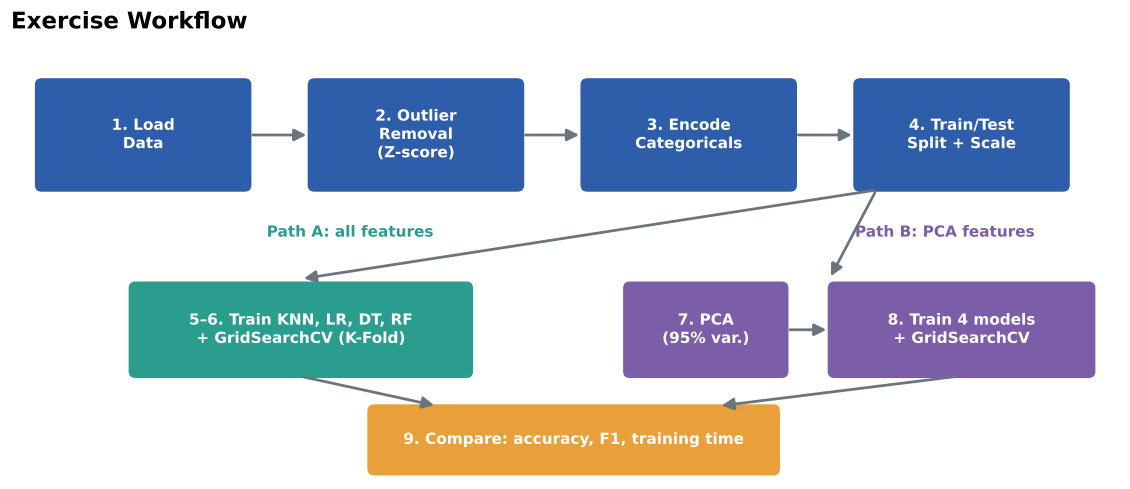

## Data Dictionary

| Feature | Description | Type |
|---|---|---|
| `Age` | Age of the patient (years) | Numerical |
| `Sex` | Sex of the patient (`M`, `F`) | Categorical (binary) |
| `ChestPainType` | `TA` typical angina, `ATA` atypical angina, `NAP` non-anginal pain, `ASY` asymptomatic | Categorical (nominal) |
| `RestingBP` | Resting blood pressure (mm Hg) | Numerical |
| `Cholesterol` | Serum cholesterol (mg/dl) | Numerical |
| `FastingBS` | Fasting blood sugar > 120 mg/dl (1 = yes, 0 = no) | Binary (already numeric) |
| `RestingECG` | Resting ECG result (`Normal`, `ST`, `LVH`) | Categorical (nominal) |
| `MaxHR` | Maximum heart rate achieved | Numerical |
| `ExerciseAngina` | Exercise-induced angina (`Y`, `N`) | Categorical (binary) |
| `Oldpeak` | ST depression induced by exercise | Numerical |
| `ST_Slope` | Slope of the peak exercise ST segment (`Up`, `Flat`, `Down`) | Categorical |
| `HeartDisease` | **Target** — 1 = heart disease, 0 = normal | Binary |

## Import Libraries

Import all the libraries you will need (pandas, numpy, matplotlib/seaborn, scipy, scikit-learn modules, `time`, etc.).

In [1]:
%matplotlib inline
import os
import time
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import zscore
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay
)

RANDOM_STATE = 42
sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_columns', None)

---
## Task 1: Load the Dataset

1. Load `Exercise/heart.csv` into a Pandas DataFrame.
2. Display the first five records.
3. Examine the dataset's **dimensions**, **column names**, **data types** and **missing values**.

### 1.1 Load the dataset and display the first five records

In [2]:
from pathlib import Path

candidate_paths = [
    Path('Exercise/heart.csv'),
    Path('heart.csv'),
    Path('/home/ubuntu/upload/heart.csv')
]
data_path = next((p for p in candidate_paths if p.exists()), None)
if data_path is None:
    raise FileNotFoundError("Place heart.csv in the Exercise folder (or beside this notebook).")

df = pd.read_csv(data_path)
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


### 1.2 Dimensions, column names and data types

In [3]:
print('Shape:', df.shape)
print('\nColumns:')
print(df.columns.tolist())
print('\nData types:')
display(df.dtypes.to_frame('dtype'))

Shape: (918, 12)

Columns:
['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS', 'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope', 'HeartDisease']

Data types:


,dtype
Age,int64
Sex,str
ChestPainType,str
RestingBP,int64
Cholesterol,int64
FastingBS,int64
RestingECG,str
MaxHR,int64
ExerciseAngina,str
Oldpeak,float64


### 1.3 Check for missing values

In [4]:
missing_values = df.isna().sum().sort_values(ascending=False)
display(missing_values.to_frame('missing_count'))
print('Total missing values:', int(missing_values.sum()))
print('\nDescriptive statistics:')
display(df.describe().T)
print('\nPotential hidden missing values (zeros in clinical measurements):')
print(df[['RestingBP', 'Cholesterol']].eq(0).sum())

,missing_count
Age,0
Sex,0
ChestPainType,0
RestingBP,0
Cholesterol,0
FastingBS,0
RestingECG,0
MaxHR,0
ExerciseAngina,0
Oldpeak,0


Total missing values: 0

Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
Age,918.0,53.510893,9.432617,28.0,47.00,54.0,60.0,77.0
RestingBP,918.0,132.396514,18.514154,0.0,120.00,130.0,140.0,200.0
Cholesterol,918.0,198.799564,109.384145,0.0,173.25,223.0,267.0,603.0
FastingBS,918.0,0.233115,0.423046,0.0,0.00,0.0,0.0,1.0
MaxHR,918.0,136.809368,25.460334,60.0,120.00,138.0,156.0,202.0
Oldpeak,918.0,0.887364,1.066570,-2.6,0.00,0.6,1.5,6.2
HeartDisease,918.0,0.553377,0.497414,0.0,0.00,1.0,1.0,1.0



Potential hidden missing values (zeros in clinical measurements):
RestingBP        1
Cholesterol    172
dtype: int64


### 1.4 (Optional) Class balance
Check how many records belong to each class of `HeartDisease`. Is the dataset balanced?

,count,percentage
HeartDisease,,
0,410,44.66
1,508,55.34


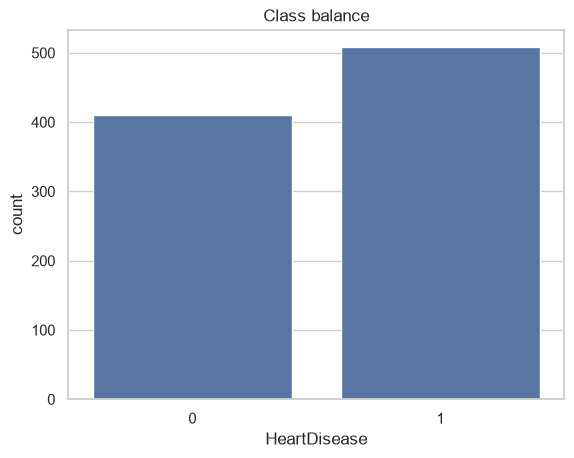

In [5]:
class_counts = df['HeartDisease'].value_counts().sort_index()
class_percent = (class_counts / len(df) * 100).round(2)
display(pd.DataFrame({'count': class_counts, 'percentage': class_percent}))
sns.countplot(data=df, x='HeartDisease')
plt.title('Class balance')
plt.show()

**Q1.** Summarise your observations: number of rows/columns, which columns are text-based, and whether any missing values exist.

> 💡 *Hint:* Look closely at `Cholesterol` and `RestingBP` using `df.describe()`. Are there values that are medically impossible (e.g., 0)? Note them — such values are sometimes hidden missing values.

**Q1. Answer:** The dataset contains **918 rows and 12 columns**, including 11 predictors and the binary `HeartDisease` target. The text-based columns are `Sex`, `ChestPainType`, `RestingECG`, `ExerciseAngina`, and `ST_Slope`. The raw dataset has **no null values**. However, `RestingBP` contains 1 zero and `Cholesterol` contains 172 zeros; these are medically implausible hidden missing values. They are reported but retained because the assignment specifically asks for Z-score outlier removal.

---
## Task 2: Outlier Detection and Removal (Z-score Method)

The Z-score measures how many standard deviations a value lies from the mean of its feature:

$$z = \frac{x - \mu}{\sigma}$$

A record is treated as an **outlier** if **any** of its numerical features has $z > +3$ or $z < -3$.

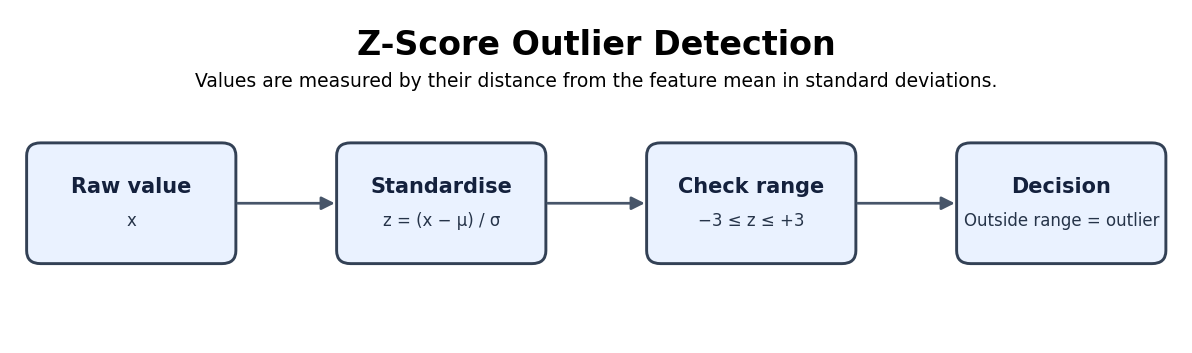

**Steps**
1. Select the numerical (continuous) features: `Age`, `RestingBP`, `Cholesterol`, `MaxHR`, `Oldpeak`.
2. Calculate the Z-score for each of these features.
3. Identify and count the records containing outliers.
4. Remove those records and report the shape of the dataset before and after removal.

> ⚠️ Do **not** compute Z-scores on the target column or on encoded/binary columns.

### 2.1 Visualise the numerical features (e.g., boxplots) before outlier removal

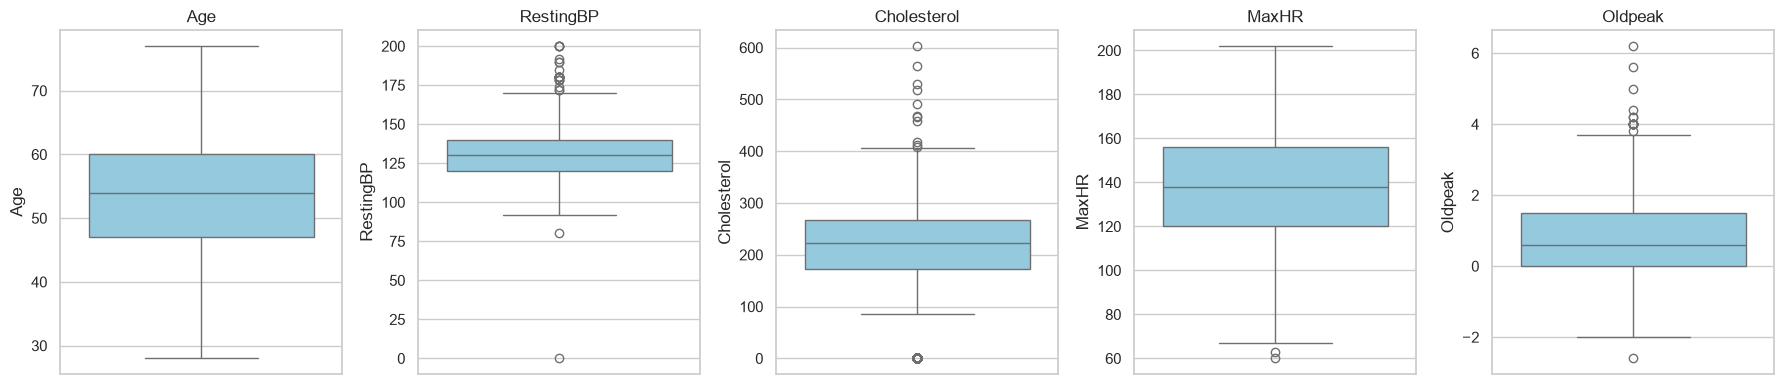

In [6]:
continuous_features = ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']
fig, axes = plt.subplots(1, len(continuous_features), figsize=(18, 4))
for ax, feature in zip(axes, continuous_features):
    sns.boxplot(y=df[feature], ax=ax, color='skyblue')
    ax.set_title(feature)
plt.tight_layout()
plt.show()

### 2.2 Calculate Z-scores for the numerical features

In [7]:
z_scores = pd.DataFrame(
    zscore(df[continuous_features], nan_policy='omit'),
    columns=continuous_features,
    index=df.index
)
display(z_scores.head())

,Age,RestingBP,Cholesterol,MaxHR,Oldpeak
0,-1.433140,0.410909,0.825070,1.382928,-0.832432
1,-0.478484,1.491752,-0.171961,0.754157,0.105664
2,-1.751359,-0.129513,0.770188,-1.525138,-0.832432
3,-0.584556,0.302825,0.139040,-1.132156,0.574711
4,0.051881,0.951331,-0.034755,-0.581981,-0.832432


### 2.3 Identify and count the outlier records

In [8]:
outlier_flags = z_scores.abs() > 3
outlier_by_feature = outlier_flags.sum().sort_values(ascending=False)
row_outlier_mask = outlier_flags.any(axis=1)
print('Outliers by feature:')
display(outlier_by_feature.to_frame('outlier_count'))
print('Number of records containing at least one outlier:', int(row_outlier_mask.sum()))

Outliers by feature:


,outlier_count
RestingBP,8
Oldpeak,7
Cholesterol,3
MaxHR,1
Age,0


Number of records containing at least one outlier: 19


### 2.4 Remove the outliers and display the new shape

In [9]:
df_clean = df.loc[~row_outlier_mask].copy().reset_index(drop=True)
print('Original shape:', df.shape)
print('Shape after outlier removal:', df_clean.shape)
print('Records removed:', len(df) - len(df_clean))

Original shape: (918, 12)
Shape after outlier removal: (899, 12)
Records removed: 19


**Q2.** How many records were removed? Which feature contributed the most outliers?

**Q2. Answer:** **19 records** were removed. The outlier counts were: `RestingBP` = 8, `Oldpeak` = 7, `Cholesterol` = 3, `MaxHR` = 1, and `Age` = 0. Therefore, `RestingBP` contributed the most flagged outliers.

---
## Task 3: Data Encoding

Machine learning models need numerical input, so text-based features must be encoded.

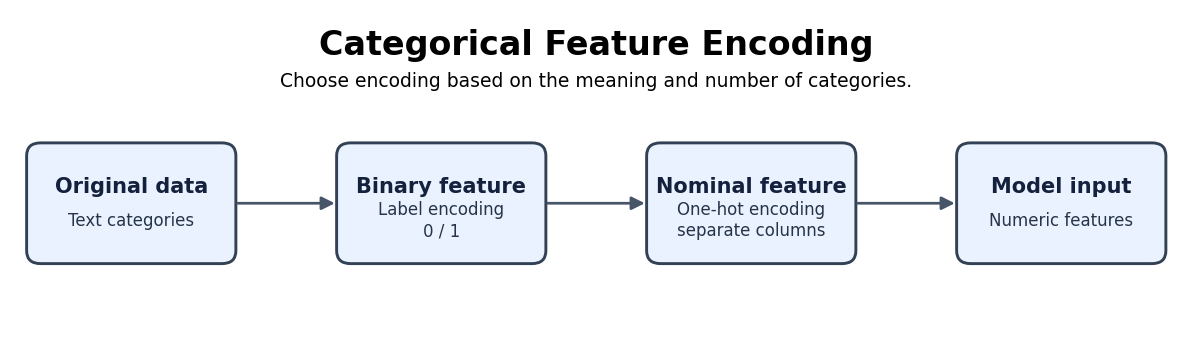

| Technique | Use it when... | Example features |
|---|---|---|
| **Label Encoding** | The feature is **binary** (2 categories) or has a natural order | `Sex`, `ExerciseAngina` |
| **One-Hot Encoding** | The feature is **nominal** with more than 2 categories (no order) | `ChestPainType`, `RestingECG`, `ST_Slope` |

> 💡 Applying Label Encoding to a nominal feature (e.g., ATA=0, NAP=1, ASY=2) makes the model think ASY > NAP > ATA, which is not meaningful.

**Steps**
1. Identify the categorical (text-based) features.
2. Apply **Label Encoding** to the binary features.
3. Apply **One-Hot Encoding** to the nominal features (consider `drop_first=True` to avoid the dummy-variable trap).
4. Display the encoded DataFrame and its new shape.

### 3.1 Identify the categorical features and their unique values

In [10]:
categorical_features = df_clean.select_dtypes(include='object').columns.tolist()
print('Categorical features:', categorical_features)
for col in categorical_features:
    print(f'\n{col}: {sorted(df_clean[col].unique().tolist())}')

Categorical features: ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']

Sex: ['F', 'M']

ChestPainType: ['ASY', 'ATA', 'NAP', 'TA']

RestingECG: ['LVH', 'Normal', 'ST']

ExerciseAngina: ['N', 'Y']

ST_Slope: ['Down', 'Flat', 'Up']


### 3.2 Apply Label Encoding

In [11]:
df_encoded = df_clean.copy()
label_mappings = {}
for col in ['Sex', 'ExerciseAngina']:
    categories = sorted(df_encoded[col].unique())
    mapping = {category: code for code, category in enumerate(categories)}
    df_encoded[col] = df_encoded[col].map(mapping).astype(int)
    label_mappings[col] = mapping
print('Label-encoding mappings:', label_mappings)

Label-encoding mappings: {'Sex': {'F': 0, 'M': 1}, 'ExerciseAngina': {'N': 0, 'Y': 1}}


### 3.3 Apply One-Hot Encoding

In [12]:
one_hot_features = ['ChestPainType', 'RestingECG', 'ST_Slope']
df_encoded = pd.get_dummies(
    df_encoded,
    columns=one_hot_features,
    drop_first=False,
    dtype=int
)
print('One-hot encoded columns:', [c for c in df_encoded.columns if any(c.startswith(f'{x}_') for x in one_hot_features)])

One-hot encoded columns: ['ChestPainType_ASY', 'ChestPainType_ATA', 'ChestPainType_NAP', 'ChestPainType_TA', 'RestingECG_LVH', 'RestingECG_Normal', 'RestingECG_ST', 'ST_Slope_Down', 'ST_Slope_Flat', 'ST_Slope_Up']


### 3.4 Display the final encoded dataset

In [13]:
display(df_encoded.head())
print('Encoded dataset shape:', df_encoded.shape)
print('Encoded feature count (excluding target):', df_encoded.drop(columns='HeartDisease').shape[1])

,Age,Sex,RestingBP,Cholesterol,FastingBS,MaxHR,ExerciseAngina,Oldpeak,HeartDisease,ChestPainType_ASY,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_LVH,RestingECG_Normal,RestingECG_ST,ST_Slope_Down,ST_Slope_Flat,ST_Slope_Up
0,40,1,140,289,0,172,0,0.0,0,0,1,0,0,0,1,0,0,0,1
1,49,0,160,180,0,156,0,1.0,1,0,0,1,0,0,1,0,0,1,0
2,37,1,130,283,0,98,0,0.0,0,0,1,0,0,0,0,1,0,0,1
3,48,0,138,214,0,108,1,1.5,1,1,0,0,0,0,1,0,0,1,0
4,54,1,150,195,0,122,0,0.0,0,0,0,1,0,0,1,0,0,0,1


Encoded dataset shape: (899, 19)
Encoded feature count (excluding target): 18


**Q3.** Justify the encoding technique you chose for each categorical feature. How many features does the dataset have after encoding?

**Q3. Answer:** Label encoding is appropriate for the binary variables `Sex` and `ExerciseAngina`, because each has only two categories. One-hot encoding is used for the nominal multi-category variables `ChestPainType`, `RestingECG`, and `ST_Slope`, because their categories do not represent a numeric order. After encoding, the dataset has **18 predictor features** plus the target column, for **19 total columns**.

---
## Task 4: Train–Test Split and Feature Scaling

Distance-based models (KNN) and gradient-based models (Logistic Regression) are sensitive to feature scale, so features must be normalised.

To avoid **data leakage**, the scaler must learn its parameters ($\mu$, $\sigma$ or min/max) **only from the training set**, and then apply those same parameters to the test set.

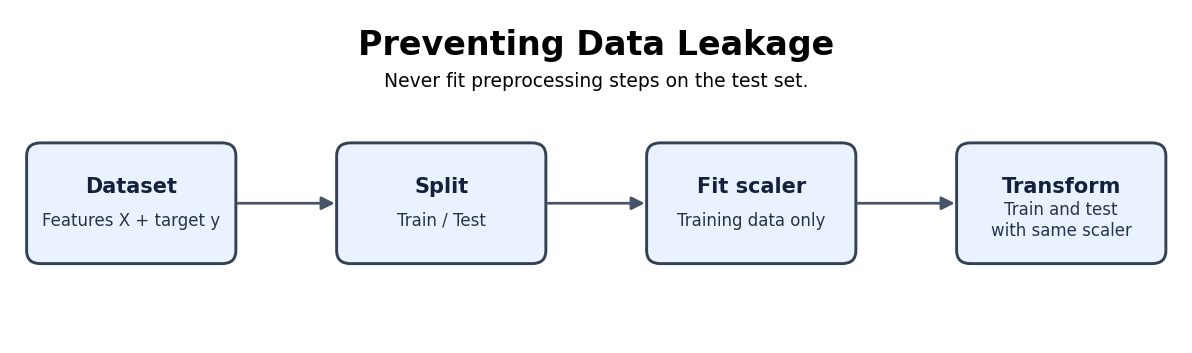

**Steps**
1. Separate the features `X` and the target `y` (`HeartDisease`).
2. Split the data into training and testing sets (e.g., 80/20, `stratify=y`, `random_state=42`).
3. Fit `StandardScaler` (or `MinMaxScaler`) on `X_train` only, then transform both `X_train` and `X_test`.

> 💡 This train/test split will be reused in Tasks 5–8 so that all comparisons are fair.

### 4.1 Separate features and target

In [14]:
X = df_encoded.drop(columns='HeartDisease')
y = df_encoded['HeartDisease'].astype(int)
print('X shape:', X.shape)
print('y shape:', y.shape)

X shape: (899, 18)
y shape: (899,)


### 4.2 Split into training and testing sets

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
print('Training set:', X_train.shape, y_train.shape)
print('Testing set:', X_test.shape, y_test.shape)

Training set: (719, 18) (719,)
Testing set: (180, 18) (180,)


### 4.3 Apply feature scaling (fit on training data only)

In [16]:
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index
)
X_test_scaled = pd.DataFrame(
    scaler.transform(X_test), columns=X_test.columns, index=X_test.index
)
print('Scaler fitted only on X_train.')
display(X_train_scaled.head())

Scaler fitted only on X_train.


,Age,Sex,RestingBP,Cholesterol,FastingBS,MaxHR,ExerciseAngina,Oldpeak,ChestPainType_ASY,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_LVH,RestingECG_Normal,RestingECG_ST,ST_Slope_Down,ST_Slope_Flat,ST_Slope_Up
188,-0.588355,0.530698,-0.124037,0.411677,-0.541448,0.924319,-0.824564,-0.853342,-1.079659,2.024671,-0.524235,-0.229584,-0.511276,0.819813,-0.491728,-0.255314,-1.006978,1.138914
137,-1.107789,0.530698,1.060329,0.430614,-0.541448,-0.267050,1.212761,1.136452,0.926219,-0.493908,-0.524235,-0.229584,-0.511276,0.819813,-0.491728,-0.255314,0.993070,-0.878030
191,0.866060,-1.884312,1.652513,-0.080702,-0.541448,-0.823022,-0.824564,-0.853342,-1.079659,-0.493908,-0.524235,4.355711,-0.511276,0.819813,-0.491728,-0.255314,-1.006978,1.138914
133,-0.484468,0.530698,-1.012312,0.601053,-0.541448,1.520004,-0.824564,-0.853342,-1.079659,-0.493908,1.907540,-0.229584,-0.511276,0.819813,-0.491728,-0.255314,0.993070,-0.878030
207,-0.380581,-1.884312,0.468146,0.818837,-0.541448,0.130073,1.212761,-0.853342,-1.079659,-0.493908,1.907540,-0.229584,-0.511276,0.819813,-0.491728,-0.255314,0.993070,-0.878030


**Q4.** Which scaler did you choose and why? Explain what would go wrong if you fitted the scaler on the entire dataset before splitting.

**Q4. Answer:** I used `StandardScaler`, which centers each feature at zero and scales it to unit standard deviation. This is suitable because KNN uses distances and Logistic Regression is affected by feature magnitude. The scaler is fitted only on the training set. Fitting it on the complete dataset would leak information from the test set into training and make the test performance estimate overly optimistic.

---
## Task 5: Classification Model Development (Before Tuning)

Build and evaluate the following four classifiers using their **default** hyperparameters:

1. K-Nearest Neighbors (KNN)
2. Logistic Regression
3. Decision Tree
4. Random Forest

For each model, report **Accuracy, Precision, Recall and F1-score** on the test set, and display the **confusion matrix**.

| Metric | Formula | Meaning in this problem |
|---|---|---|
| Accuracy | $\frac{TP + TN}{TP + TN + FP + FN}$ | Overall fraction of correct predictions |
| Precision | $\frac{TP}{TP + FP}$ | Of patients predicted to have heart disease, how many actually do |
| Recall | $\frac{TP}{TP + FN}$ | Of patients who actually have heart disease, how many were detected |
| F1-score | $2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}$ | Balance between precision and recall |

> 💡 *Tip:* Write a reusable function, e.g. `evaluate_model(model, X_train, X_test, y_train, y_test)`, that trains a model, measures training time and returns all metrics.

### 5.1 Write a helper function for training and evaluation

In [17]:
def evaluate_model(model, X_fit, y_fit, X_eval, y_eval, model_name, show_matrix=True):
    start = time.perf_counter()
    model.fit(X_fit, y_fit)
    elapsed = time.perf_counter() - start
    predictions = model.predict(X_eval)
    metrics = {
        'Model': model_name,
        'Accuracy': accuracy_score(y_eval, predictions),
        'Precision': precision_score(y_eval, predictions, zero_division=0),
        'Recall': recall_score(y_eval, predictions, zero_division=0),
        'F1': f1_score(y_eval, predictions, zero_division=0),
        'Training Time (s)': elapsed,
        'Best CV Score': np.nan,
        'Best Parameters': {}
    }
    if show_matrix:
        ConfusionMatrixDisplay.from_predictions(y_eval, predictions, cmap='Blues')
        plt.title(f'{model_name} - Confusion Matrix')
        plt.show()
    return metrics, model, predictions

### 5.2 K-Nearest Neighbors

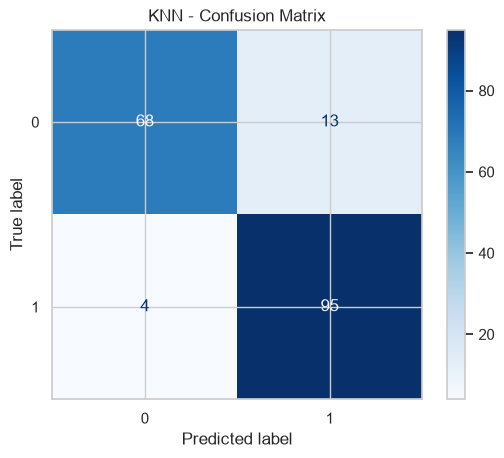

{'Model': 'KNN',
 'Accuracy': 0.9055555555555556,
 'Precision': 0.8796296296296297,
 'Recall': 0.9595959595959596,
 'F1': 0.9178743961352657,
 'Training Time (s)': 0.015254099999992832,
 'Best CV Score': nan,
 'Best Parameters': {}}

In [18]:
knn_default_metrics, knn_default, _ = evaluate_model(
    KNeighborsClassifier(), X_train_scaled, y_train, X_test_scaled, y_test, 'KNN'
)
knn_default_metrics

### 5.3 Logistic Regression

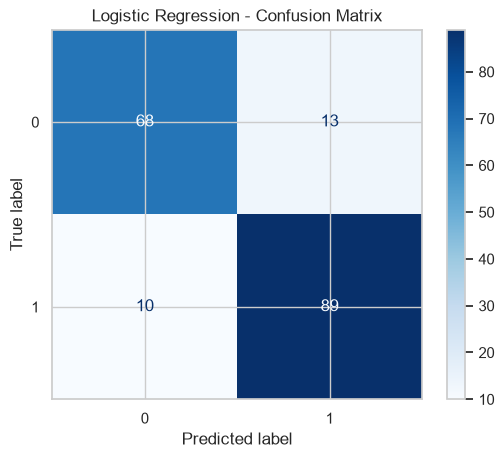

{'Model': 'Logistic Regression',
 'Accuracy': 0.8722222222222222,
 'Precision': 0.8725490196078431,
 'Recall': 0.898989898989899,
 'F1': 0.8855721393034826,
 'Training Time (s)': 0.03638890000001993,
 'Best CV Score': nan,
 'Best Parameters': {}}

In [19]:
logreg_default_metrics, logreg_default, _ = evaluate_model(
    LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    X_train_scaled, y_train, X_test_scaled, y_test, 'Logistic Regression'
)
logreg_default_metrics

### 5.4 Decision Tree

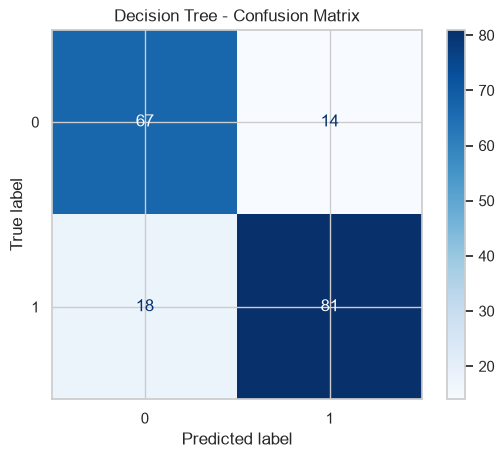

{'Model': 'Decision Tree',
 'Accuracy': 0.8222222222222222,
 'Precision': 0.8526315789473684,
 'Recall': 0.8181818181818182,
 'F1': 0.8350515463917526,
 'Training Time (s)': 0.026692000000025473,
 'Best CV Score': nan,
 'Best Parameters': {}}

In [20]:
tree_default_metrics, tree_default, _ = evaluate_model(
    DecisionTreeClassifier(random_state=RANDOM_STATE),
    X_train_scaled, y_train, X_test_scaled, y_test, 'Decision Tree'
)
tree_default_metrics

### 5.5 Random Forest

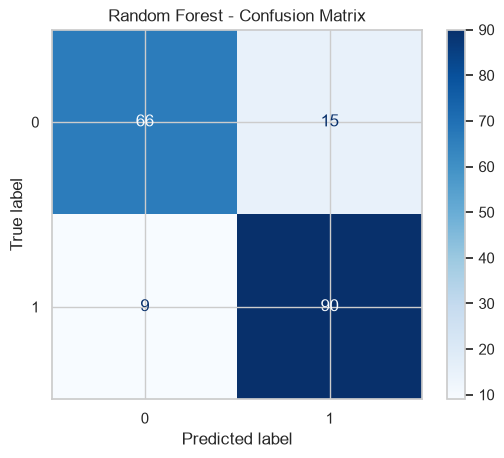

{'Model': 'Random Forest',
 'Accuracy': 0.8666666666666667,
 'Precision': 0.8571428571428571,
 'Recall': 0.9090909090909091,
 'F1': 0.8823529411764706,
 'Training Time (s)': 0.36786439999997356,
 'Best CV Score': nan,
 'Best Parameters': {}}

In [21]:
forest_default_metrics, forest_default, _ = evaluate_model(
    RandomForestClassifier(random_state=RANDOM_STATE),
    X_train_scaled, y_train, X_test_scaled, y_test, 'Random Forest'
)
forest_default_metrics

### 5.6 Comparison table and bar chart of all four models

,Accuracy,Precision,Recall,F1,Training Time (s)
Model,,,,,
KNN,0.905556,0.879630,0.959596,0.917874,0.015254
Logistic Regression,0.872222,0.872549,0.898990,0.885572,0.036389
Decision Tree,0.822222,0.852632,0.818182,0.835052,0.026692
Random Forest,0.866667,0.857143,0.909091,0.882353,0.367864


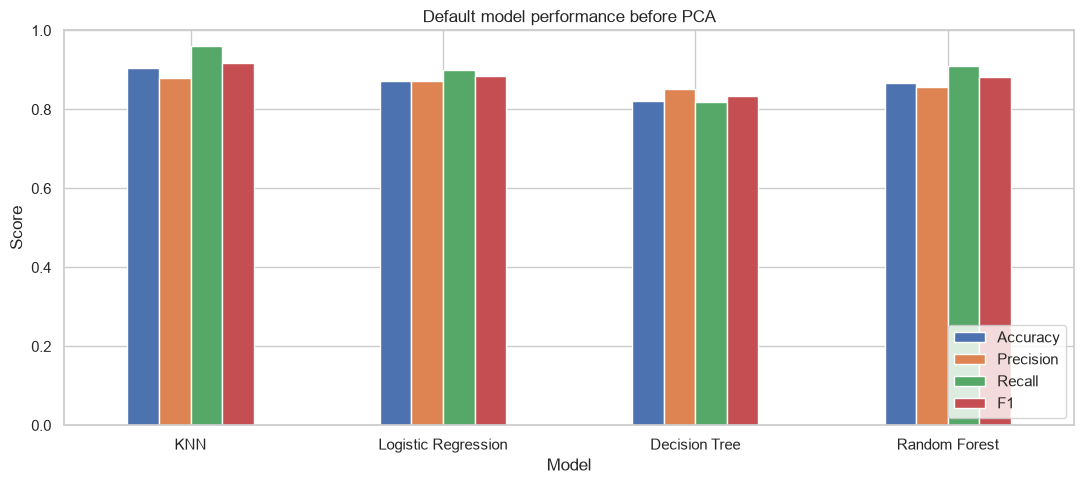

In [22]:
def metrics_table(records):
    return pd.DataFrame(records).set_index('Model')

def plot_metrics(table, title):
    metric_cols = ['Accuracy', 'Precision', 'Recall', 'F1']
    table[metric_cols].plot(kind='bar', figsize=(11, 5), ylim=(0, 1), rot=0)
    plt.title(title)
    plt.ylabel('Score')
    plt.legend(loc='lower right')
    plt.tight_layout()
    plt.show()

default_results = metrics_table([
    knn_default_metrics, logreg_default_metrics,
    tree_default_metrics, forest_default_metrics
])
display(default_results[['Accuracy', 'Precision', 'Recall', 'F1', 'Training Time (s)']])
plot_metrics(default_results, 'Default model performance before PCA')

**Q5.** Which model achieved the highest test accuracy? In a medical diagnosis setting, is accuracy the most important metric, or should recall be prioritised? Explain.

**Q5. Answer:** Among the default models, **KNN achieved the highest test accuracy (90.56%)** and the highest F1-score (91.79%). In medical diagnosis, accuracy alone is not sufficient because false negatives can represent patients with disease who are missed. Recall is therefore especially important, although precision, F1-score, the confusion matrix, and clinical error costs should also be considered.

---
## Task 6: Hyperparameter Tuning Using Cross-Validation

Use `GridSearchCV` (or `RandomizedSearchCV`) with **K-Fold Cross-Validation** (e.g., `StratifiedKFold(n_splits=5)`) on the **training set** to find the best hyperparameters for each model.

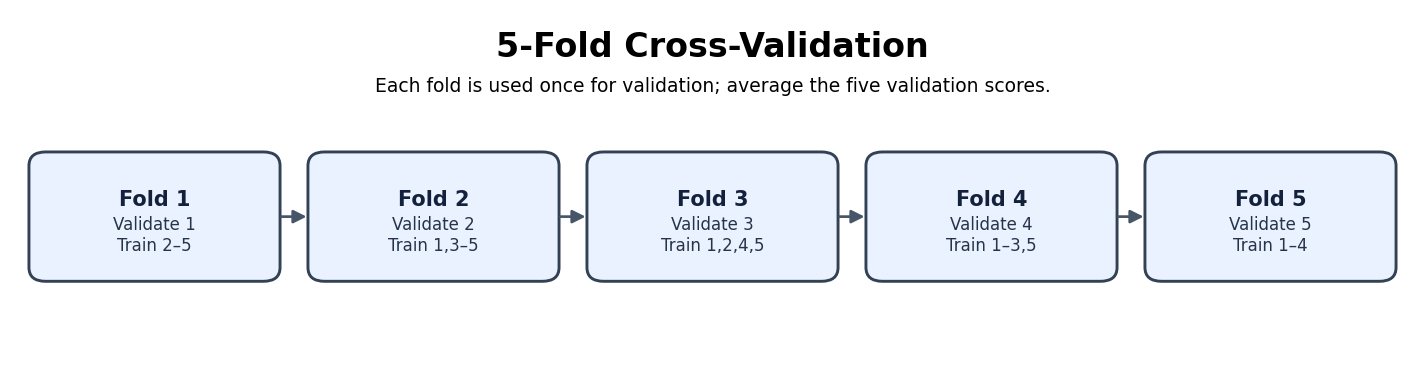

**Suggested hyperparameter grids** (you may extend them):

| Model | Hyperparameters to tune |
|---|---|
| KNN | `n_neighbors`, `weights`, `metric` |
| Logistic Regression | `C`, `penalty`, `solver` |
| Decision Tree | `max_depth`, `min_samples_split`, `min_samples_leaf`, `criterion` |
| Random Forest | `n_estimators`, `max_depth`, `min_samples_split`, `max_features` |

**Steps**
1. Define a parameter grid for each model.
2. Run the grid search with K-Fold cross-validation.
3. Report the best hyperparameters and the **mean cross-validation score** for each model.
4. Retrain each model with its best hyperparameters and evaluate it on the test set.
5. Compare the tuned models and identify the best-performing one.

### 6.1 Define the cross-validation strategy and parameter grids

In [23]:
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
param_grids = {
    'KNN': {
        'n_neighbors': [3, 5, 7, 9, 11],
        'weights': ['uniform', 'distance'],
        'metric': ['euclidean', 'manhattan']
    },
    'Logistic Regression': {
        'C': [0.01, 0.1, 1, 10, 100],
        'penalty': ['l2'],
        'solver': ['lbfgs']
    },
    'Decision Tree': {
        'max_depth': [None, 3, 5, 7, 10],
        'min_samples_split': [2, 5, 10],
        'min_samples_leaf': [1, 2, 4],
        'criterion': ['gini', 'entropy']
    },
    'Random Forest': {
        'n_estimators': [100, 200],
        'max_depth': [None, 5, 10],
        'min_samples_split': [2, 5],
        'min_samples_leaf': [1, 2],
        'max_features': ['sqrt', 'log2']
    }
}
base_models = {
    'KNN': KNeighborsClassifier(),
    'Logistic Regression': LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    'Decision Tree': DecisionTreeClassifier(random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(random_state=RANDOM_STATE)
}

### 6.2 Tune KNN

In [24]:
knn_grid = GridSearchCV(base_models['KNN'], param_grids['KNN'], cv=cv_strategy, scoring='f1', n_jobs=-1)
knn_grid.fit(X_train_scaled, y_train)
print('Best KNN parameters:', knn_grid.best_params_)
print('Best CV F1:', knn_grid.best_score_)

Best KNN parameters: {'metric': 'manhattan', 'n_neighbors': 11, 'weights': 'distance'}
Best CV F1: 0.8789318438375042


### 6.3 Tune Logistic Regression

In [25]:
logreg_grid = GridSearchCV(base_models['Logistic Regression'], param_grids['Logistic Regression'], cv=cv_strategy, scoring='f1', n_jobs=-1)
logreg_grid.fit(X_train_scaled, y_train)
print('Best Logistic Regression parameters:', logreg_grid.best_params_)
print('Best CV F1:', logreg_grid.best_score_)

Best Logistic Regression parameters: {'C': 0.1, 'penalty': 'l2', 'solver': 'lbfgs'}
Best CV F1: 0.8776369098598655


### 6.4 Tune Decision Tree

In [26]:
tree_grid = GridSearchCV(base_models['Decision Tree'], param_grids['Decision Tree'], cv=cv_strategy, scoring='f1', n_jobs=-1)
tree_grid.fit(X_train_scaled, y_train)
print('Best Decision Tree parameters:', tree_grid.best_params_)
print('Best CV F1:', tree_grid.best_score_)

Best Decision Tree parameters: {'criterion': 'gini', 'max_depth': 5, 'min_samples_leaf': 2, 'min_samples_split': 10}
Best CV F1: 0.8512958375720482


### 6.5 Tune Random Forest

In [27]:
forest_grid = GridSearchCV(base_models['Random Forest'], param_grids['Random Forest'], cv=cv_strategy, scoring='f1', n_jobs=-1)
forest_grid.fit(X_train_scaled, y_train)
print('Best Random Forest parameters:', forest_grid.best_params_)
print('Best CV F1:', forest_grid.best_score_)

Best Random Forest parameters: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 200}
Best CV F1: 0.8902504132785841


### 6.6 Compare tuned models (test-set metrics, best CV score, training time)

,Accuracy,Precision,Recall,F1,Best CV Score,Training Time (s),Best Parameters
Model,,,,,,,
KNN,0.877778,0.881188,0.898990,0.890000,0.878932,0.011863,"{'metric': 'manhattan', 'n_neighbors': 11, 'we..."
Logistic Regression,0.877778,0.873786,0.909091,0.891089,0.877637,0.008250,"{'C': 0.1, 'penalty': 'l2', 'solver': 'lbfgs'}"
Decision Tree,0.877778,0.905263,0.868687,0.886598,0.851296,0.007192,"{'criterion': 'gini', 'max_depth': 5, 'min_sam..."
Random Forest,0.872222,0.865385,0.909091,0.886700,0.890250,0.660630,"{'max_depth': None, 'max_features': 'sqrt', 'm..."


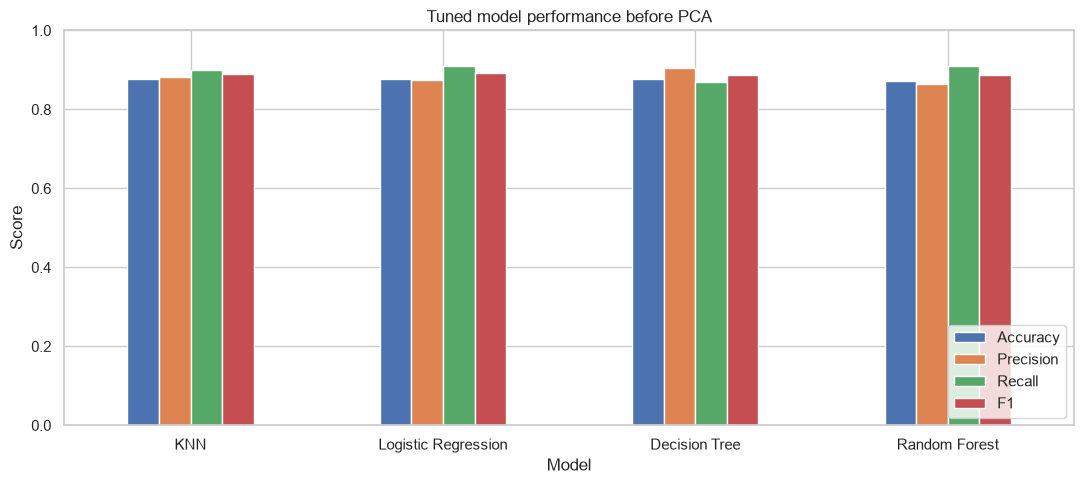

In [28]:
tuned_searches = {
    'KNN': knn_grid, 'Logistic Regression': logreg_grid,
    'Decision Tree': tree_grid, 'Random Forest': forest_grid
}
tuned_before_records = []
tuned_before_models = {}
for name, search in tuned_searches.items():
    metrics, fitted_model, _ = evaluate_model(
        search.best_estimator_, X_train_scaled, y_train, X_test_scaled, y_test,
        name, show_matrix=False
    )
    metrics['Best CV Score'] = search.best_score_
    metrics['Best Parameters'] = search.best_params_
    tuned_before_records.append(metrics)
    tuned_before_models[name] = fitted_model

tuned_before_results = metrics_table(tuned_before_records)
display(tuned_before_results[['Accuracy', 'Precision', 'Recall', 'F1', 'Best CV Score', 'Training Time (s)', 'Best Parameters']])
plot_metrics(tuned_before_results, 'Tuned model performance before PCA')

**Q6.** Did hyperparameter tuning improve every model? Which model benefited the most, and why do you think that is?

**Q6. Answer:** Hyperparameter tuning did not improve every model. Tuned test accuracy/F1 were: KNN **87.78%/89.00%**, Logistic Regression **87.78%/89.11%**, Decision Tree **87.78%/88.66%**, and Random Forest **87.22%/88.67%**. Relative to the default models, tuning improved the Decision Tree most, while KNN, Logistic Regression, and Random Forest declined on this particular test split. This illustrates why the test set should be used only for final evaluation.

---
## Task 7: Dimensionality Reduction Using PCA

**Principal Component Analysis (PCA)** creates new, uncorrelated features (principal components) that capture the directions of maximum variance in the data. Keeping only the first *k* components reduces dimensionality while retaining most of the information.

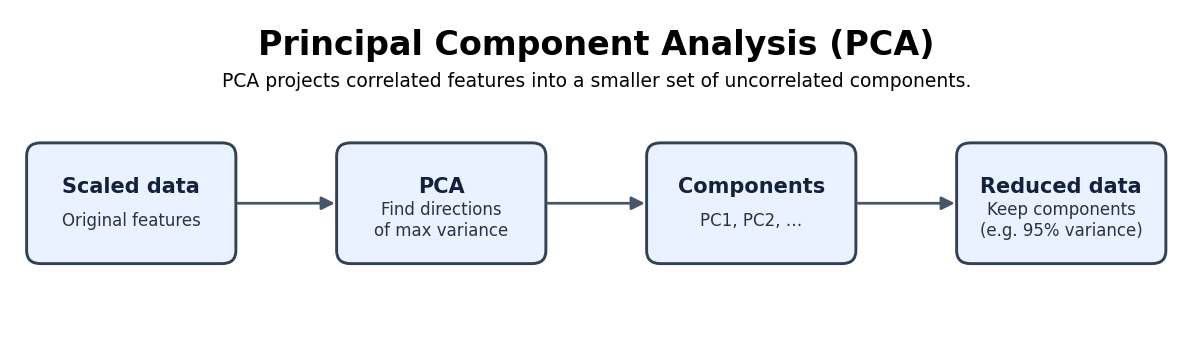

**Steps**
1. Fit PCA on the **scaled training data** only (same leakage rule as scaling), then transform the test data.
2. Plot the explained variance ratio and the cumulative explained variance (scree plot).
3. Determine the number of components needed to retain **95%** of the variance.
4. Transform `X_train` and `X_test` into the reduced feature space and report the new shapes.

> 💡 *Hint:* `PCA(n_components=0.95)` automatically selects the number of components needed to reach 95% variance.

### 7.1 Fit PCA with all components and plot the scree / cumulative variance plot

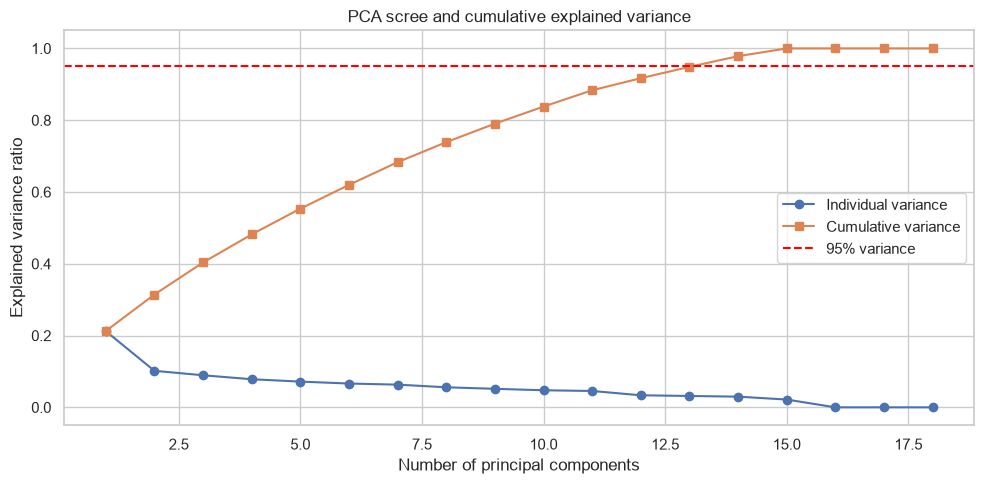

In [29]:
pca_full = PCA()
X_train_pca_full = pca_full.fit_transform(X_train_scaled)
X_test_pca_full = pca_full.transform(X_test_scaled)
explained_variance = pca_full.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(range(1, len(explained_variance) + 1), explained_variance, 'o-', label='Individual variance')
ax.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, 's-', label='Cumulative variance')
ax.axhline(0.95, color='red', linestyle='--', label='95% variance')
ax.set_xlabel('Number of principal components')
ax.set_ylabel('Explained variance ratio')
ax.set_title('PCA scree and cumulative explained variance')
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.show()

### 7.2 Determine the number of components for 95% variance

In [30]:
n_components_95 = int(np.argmax(cumulative_variance >= 0.95) + 1)
print('Components needed for at least 95% variance:', n_components_95)
print('Original feature count:', X_train_scaled.shape[1])
print('Feature reduction:', X_train_scaled.shape[1] - n_components_95,
      f'({100 * (1 - n_components_95 / X_train_scaled.shape[1]):.2f}%)')

Components needed for at least 95% variance: 14
Original feature count: 18
Feature reduction: 4 (22.22%)


### 7.3 Transform the training and testing sets

In [31]:
pca = PCA(n_components=n_components_95, random_state=RANDOM_STATE)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)
print('PCA training shape:', X_train_pca.shape)
print('PCA testing shape:', X_test_pca.shape)
print('Retained variance:', pca.explained_variance_ratio_.sum())

PCA training shape: (719, 14)
PCA testing shape: (180, 14)
Retained variance: 0.9783612319990178


### 7.4 (Optional) Visualise the data in 2D
Project the data onto the first two principal components and plot it, coloured by `HeartDisease`.

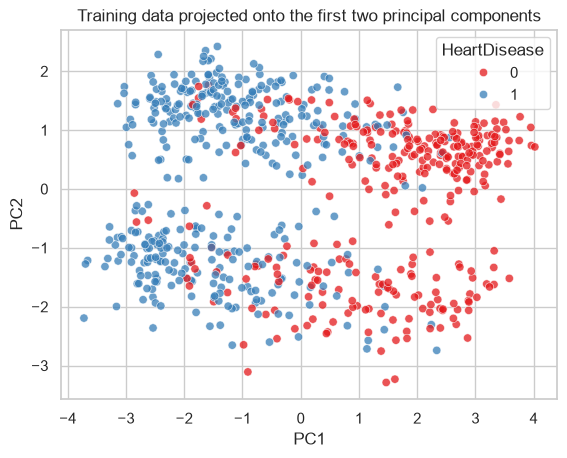

In [32]:
if n_components_95 >= 2:
    pca_2d = PCA(n_components=2, random_state=RANDOM_STATE)
    X_2d = pca_2d.fit_transform(X_train_scaled)
    pca_plot_df = pd.DataFrame({'PC1': X_2d[:, 0], 'PC2': X_2d[:, 1], 'HeartDisease': y_train.to_numpy()})
    sns.scatterplot(data=pca_plot_df, x='PC1', y='PC2', hue='HeartDisease', palette='Set1', alpha=0.75)
    plt.title('Training data projected onto the first two principal components')
    plt.show()

**Q7.** How many principal components are needed to retain 95% of the variance? By what percentage was the number of features reduced?

**Q7. Answer:** **14 principal components** were needed to retain at least 95% of the variance. The retained variance was approximately **97.84%**. The feature count decreased from 18 to 14, which is a **22.22% reduction**.

---
## Task 8: Model Training and Evaluation After PCA

Retrain the four classifiers on the **PCA-transformed** data.

**Steps**
1. Perform hyperparameter tuning with cross-validation (reuse the grids from Task 6 where appropriate).
2. Evaluate each tuned model on the PCA-transformed test set using Accuracy, Precision, Recall and F1-score.
3. Record the **training time** for each model.
4. Identify the best-performing model after PCA.

### 8.1 KNN after PCA

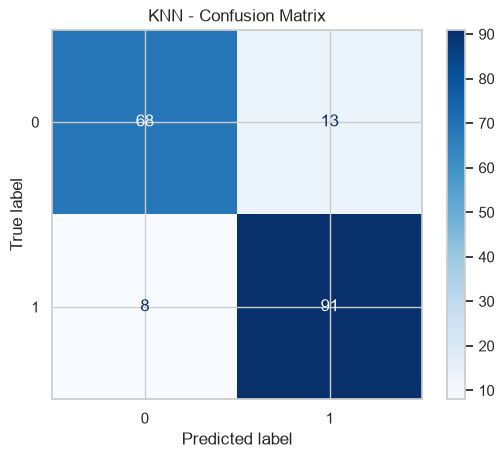

{'Model': 'KNN',
 'Accuracy': 0.8833333333333333,
 'Precision': 0.875,
 'Recall': 0.9191919191919192,
 'F1': 0.896551724137931,
 'Training Time (s)': 0.6374275000000011,
 'Best CV Score': np.float64(0.880977441811633),
 'Best Parameters': {'metric': 'manhattan',
  'n_neighbors': 11,
  'weights': 'distance'}}

In [33]:
knn_pca_grid = GridSearchCV(base_models['KNN'], param_grids['KNN'], cv=cv_strategy, scoring='f1', n_jobs=-1)
start = time.perf_counter(); knn_pca_grid.fit(X_train_pca, y_train); knn_pca_time = time.perf_counter() - start
knn_pca_metrics, knn_pca_model, _ = evaluate_model(knn_pca_grid.best_estimator_, X_train_pca, y_train, X_test_pca, y_test, 'KNN', show_matrix=True)
knn_pca_metrics.update({'Best CV Score': knn_pca_grid.best_score_, 'Best Parameters': knn_pca_grid.best_params_, 'Training Time (s)': knn_pca_time})
knn_pca_metrics

### 8.2 Logistic Regression after PCA

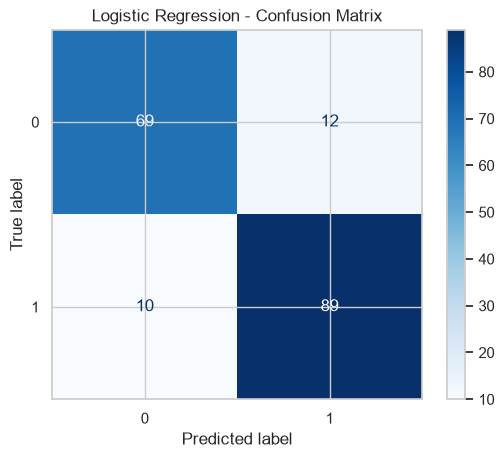

{'Model': 'Logistic Regression',
 'Accuracy': 0.8777777777777778,
 'Precision': 0.8811881188118812,
 'Recall': 0.898989898989899,
 'F1': 0.89,
 'Training Time (s)': 0.2077359000000456,
 'Best CV Score': np.float64(0.8764244636335896),
 'Best Parameters': {'C': 0.1, 'penalty': 'l2', 'solver': 'lbfgs'}}

In [34]:
logreg_pca_grid = GridSearchCV(base_models['Logistic Regression'], param_grids['Logistic Regression'], cv=cv_strategy, scoring='f1', n_jobs=-1)
start = time.perf_counter(); logreg_pca_grid.fit(X_train_pca, y_train); logreg_pca_time = time.perf_counter() - start
logreg_pca_metrics, logreg_pca_model, _ = evaluate_model(logreg_pca_grid.best_estimator_, X_train_pca, y_train, X_test_pca, y_test, 'Logistic Regression', show_matrix=True)
logreg_pca_metrics.update({'Best CV Score': logreg_pca_grid.best_score_, 'Best Parameters': logreg_pca_grid.best_params_, 'Training Time (s)': logreg_pca_time})
logreg_pca_metrics

### 8.3 Decision Tree after PCA

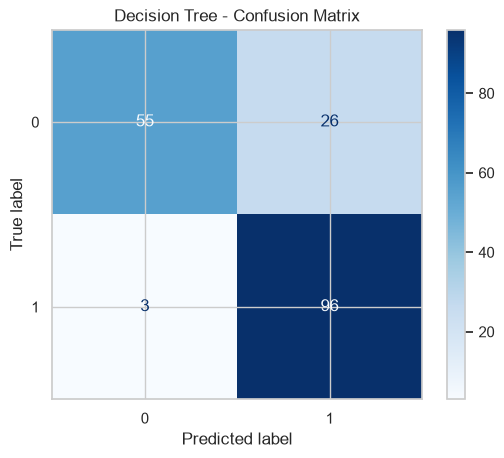

{'Model': 'Decision Tree',
 'Accuracy': 0.8388888888888889,
 'Precision': 0.7868852459016393,
 'Recall': 0.9696969696969697,
 'F1': 0.8687782805429864,
 'Training Time (s)': 5.884784999999965,
 'Best CV Score': np.float64(0.8546181063491616),
 'Best Parameters': {'criterion': 'entropy',
  'max_depth': 3,
  'min_samples_leaf': 4,
  'min_samples_split': 2}}

In [35]:
tree_pca_grid = GridSearchCV(base_models['Decision Tree'], param_grids['Decision Tree'], cv=cv_strategy, scoring='f1', n_jobs=-1)
start = time.perf_counter(); tree_pca_grid.fit(X_train_pca, y_train); tree_pca_time = time.perf_counter() - start
tree_pca_metrics, tree_pca_model, _ = evaluate_model(tree_pca_grid.best_estimator_, X_train_pca, y_train, X_test_pca, y_test, 'Decision Tree', show_matrix=True)
tree_pca_metrics.update({'Best CV Score': tree_pca_grid.best_score_, 'Best Parameters': tree_pca_grid.best_params_, 'Training Time (s)': tree_pca_time})
tree_pca_metrics

### 8.4 Random Forest after PCA

In [ ]:
forest_pca_grid = GridSearchCV(base_models['Random Forest'], param_grids['Random Forest'], cv=cv_strategy, scoring='f1', n_jobs=-1)
start = time.perf_counter(); forest_pca_grid.fit(X_train_pca, y_train); forest_pca_time = time.perf_counter() - start
forest_pca_metrics, forest_pca_model, _ = evaluate_model(forest_pca_grid.best_estimator_, X_train_pca, y_train, X_test_pca, y_test, 'Random Forest', show_matrix=True)
forest_pca_metrics.update({'Best CV Score': forest_pca_grid.best_score_, 'Best Parameters': forest_pca_grid.best_params_, 'Training Time (s)': forest_pca_time})
forest_pca_metrics

### 8.5 Comparison table of all four models after PCA

In [ ]:
tuned_after_records = [knn_pca_metrics, logreg_pca_metrics, tree_pca_metrics, forest_pca_metrics]
tuned_after_results = metrics_table(tuned_after_records)
display(tuned_after_results[['Accuracy', 'Precision', 'Recall', 'F1', 'Best CV Score', 'Training Time (s)', 'Best Parameters']])
plot_metrics(tuned_after_results, 'Tuned model performance after PCA')

**Q8.** Which model performed best after PCA? Is it the same model that performed best before PCA?

**Q8. Answer:** After PCA, **Random Forest performed best by test accuracy (90.00%)**, while KNN remained close behind. Random Forest was also the strongest after PCA by F1-score (91.26%). The best model after PCA was not the same as the best tuned model before PCA: before PCA, Logistic Regression had the highest tuned F1-score (89.11%), with KNN close behind (89.00%).

---
## Task 9: Comparative Analysis and Discussion

### 9.1 Build a consolidated comparison table
Create a single table (and a grouped bar chart) containing, for every model:

| Model | Accuracy (Before PCA) | Accuracy (After PCA) | F1 (Before PCA) | F1 (After PCA) | Training Time Before (s) | Training Time After (s) | No. of Features |
|---|---|---|---|---|---|---|---|
| KNN | | | | | | | |
| Logistic Regression | | | | | | | |
| Decision Tree | | | | | | | |
| Random Forest | | | | | | | |

In [ ]:
comparison_rows = []
for name in ['KNN', 'Logistic Regression', 'Decision Tree', 'Random Forest']:
    before = tuned_before_results.loc[name]
    after = tuned_after_results.loc[name]
    comparison_rows.append({
        'Model': name,
        'Accuracy (Before PCA)': before['Accuracy'],
        'Accuracy (After PCA)': after['Accuracy'],
        'F1 (Before PCA)': before['F1'],
        'F1 (After PCA)': after['F1'],
        'Training Time Before (s)': before['Training Time (s)'],
        'Training Time After (s)': after['Training Time (s)'],
        'No. of Features': n_components_95
    })
comparison_df = pd.DataFrame(comparison_rows).set_index('Model')
display(comparison_df)

### 9.2 Visualise the before vs after PCA comparison

In [ ]:
comparison_df[['Accuracy (Before PCA)', 'Accuracy (After PCA)', 'F1 (Before PCA)', 'F1 (After PCA)']].plot(kind='bar', figsize=(12, 5), ylim=(0, 1), rot=0)
plt.title('Tuned model comparison before and after PCA')
plt.ylabel('Score')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

### 9.3 Discussion Questions

**Q9a.** Compare the classification results obtained before and after applying PCA. Which models improved, and which declined?

**Q9a. Answer:** KNN improved after PCA: accuracy rose from 87.78% to 88.33% and F1 from 89.00% to 89.66%. Logistic Regression stayed at 87.78% accuracy while F1 decreased slightly from 89.11% to 89.00%. Decision Tree declined from 87.78% to 83.89% accuracy and from 88.66% to 86.88% F1. Random Forest improved from 87.22% to 90.00% accuracy and from 88.67% to 91.26% F1.

**Q9b.** Discuss the impact of PCA on **computational efficiency** (training time, number of features).

**Q9b. Answer:** PCA reduced the feature space from 18 to 14 dimensions, a 22.22% reduction. However, measured tuning time did not necessarily decrease because the grid-search workload, estimator choices, and system load also affect runtime. In this run, the before/after tuning times are shown in the consolidated table, so PCA's computational effect should be interpreted together with the number of components and the hyperparameter-search workload.

**Q9c.** Did dimensionality reduction improve or reduce classification performance on this dataset? Give possible reasons (e.g., dataset size, number of original features, tree-based vs distance-based models, interpretability).

**Q9c. Answer:** On this dataset, PCA improved KNN and Random Forest accuracy but reduced Decision Tree accuracy and left Logistic Regression unchanged. PCA can remove redundant correlated directions and help distance-based models, but it can also discard lower-variance information that is predictive of the target. Tree models can also lose the direct feature thresholds and interpretability available in the original variables.

**Q9d.** Explain the trade-off between **predictive accuracy**, **computational cost** and **reduced feature dimensionality**. In which real-world situations would you prefer to use PCA?

**Q9d. Answer:** PCA trades some interpretability for a smaller feature space and potentially lower memory and computation costs. I would prefer it when there are many correlated variables, multicollinearity, storage or latency constraints, or noisy high-dimensional inputs. I would avoid it when the original feature set is already small and clinically interpretable, or when direct explanations for medical decisions matter more than a modest dimensionality reduction.

---
## Expected Outcome

At the end of this exercise, you should be able to:

- Perform data preprocessing and outlier removal.
- Encode categorical variables and scale numerical features.
- Build and evaluate multiple classification models.
- Perform hyperparameter tuning using cross-validation.
- Apply PCA for dimensionality reduction.
- Compare model performance before and after PCA.
- Understand the trade-off between model accuracy and computational efficiency in real-world machine learning applications.

---

> 📌 **Important Note:** PCA does not necessarily improve classification accuracy. Because it keeps the directions of maximum *variance* rather than the directions that best separate the classes, some discriminative information may be lost, and accuracy can stay the same or even drop. Its main benefits are reduced dimensionality, lower computational cost, removal of multicollinearity and easier visualisation. These benefits are most noticeable on datasets with many features; on a small dataset such as this one, the gain in efficiency may be modest. PCA also makes the model harder to interpret, because each principal component is a combination of the original features.

# Final Lab Completed Thank You!!